# LSTM-GRU-Practice

In [1]:
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, GRU, Dense, Dropout

print("Libraries imported successfully!")


c:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\site-packages\google\api_core\_python_version_support.py:254: FutureWarning: You are using a Python version (3.11.4) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


Libraries imported successfully!


In [2]:
np.random.seed(42)

time = np.arange(500)

motor_current = (
    2
    + 0.002 * time
    + 0.5 * np.sin(2 * np.pi * time / 50)
    + np.random.normal(0, 0.08, len(time))
)

df = pd.DataFrame({
    "time": time,
    "motor_current": motor_current
})

df.head()

,time,motor_current
0,0,2.039737
1,1,2.053605
2,2,2.180160
3,3,2.311905
4,4,2.230145


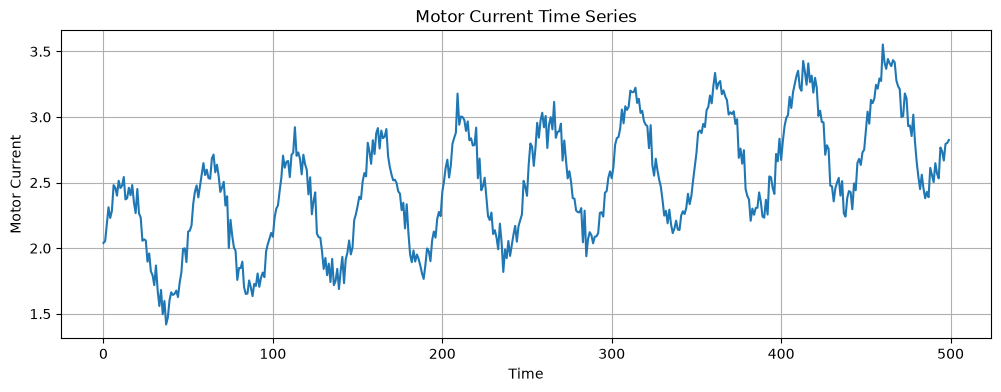

In [3]:
plt.figure(figsize=(12, 4))

plt.plot(df["time"], df["motor_current"])

plt.title("Motor Current Time Series")
plt.xlabel("Time")
plt.ylabel("Motor Current")

plt.grid(True)
plt.show()

In [4]:
values = df[["motor_current"]].values

split_index = int(len(values) * 0.8)

train_data = values[:split_index]
test_data = values[split_index:]

print("Total records:", len(values))
print("Training records:", len(train_data))
print("Testing records:", len(test_data))

Total records: 500
Training records: 400
Testing records: 100



First five rows of dataset:
   time  motor_current
0     0       2.039737
1     1       2.053605
2     2       2.180160
3     3       2.311905
4     4       2.230145

Dataset shape:
(1200, 2)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   time           1200 non-null   int64  
 1   motor_current  1200 non-null   float64
dtypes: float64(1), int64(1)
memory usage: 18.9 KB
None


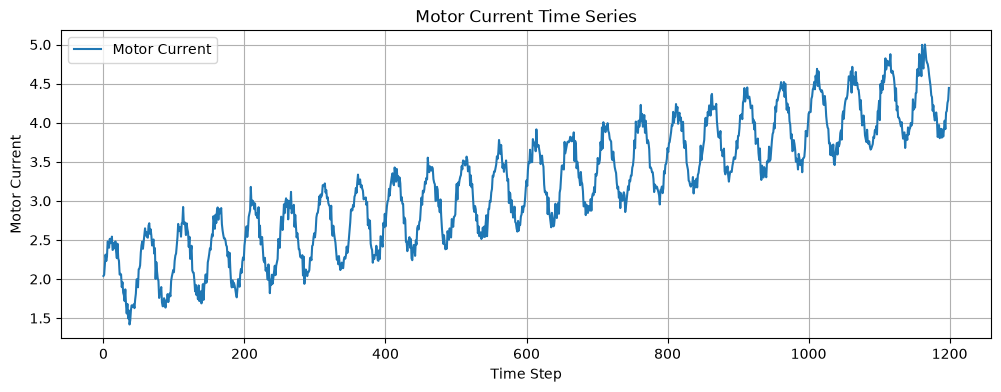


Training data shape: (960, 1)
Testing data shape: (240, 1)

X_train shape: (930, 30, 1)
y_train shape: (930, 1)
X_test shape: (240, 30, 1)
y_test shape: (240, 1)

LSTM MODEL SUMMARY


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,897 (19.13 KB)

 Trainable params: 4,897 (19.13 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 32)             │         3,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,905 (15.25 KB)

 Trainable params: 3,905 (15.25 KB)

 Non-trainable params: 0 (0.00 B)


Training LSTM model...
Epoch 1/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 11s 85ms/step - loss: 0.0798 - val_loss: 0.0234
Epoch 2/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0328 - val_loss: 0.0126
Epoch 3/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 83ms/step - loss: 0.0211 - val_loss: 0.0106
Epoch 4/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 77ms/step - loss: 0.0156 - val_loss: 0.0077
Epoch 5/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.0130 - val_loss: 0.0068
Epoch 6/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0112 - val_loss: 0.0062
Epoch 7/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0098 - val_loss: 0.0057
Epoch 8/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - loss: 0.0083 - val_loss: 0.0049
Epoch 9/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - loss: 0.0072 - val_loss: 0.0048
Epoch 10/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0077 - val_loss: 0.0043
Epoch 11/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0078 - val_loss: 0.0034
Epoch 12/30
27/27 ━━━━━━━━━━━━━━━━━━━━

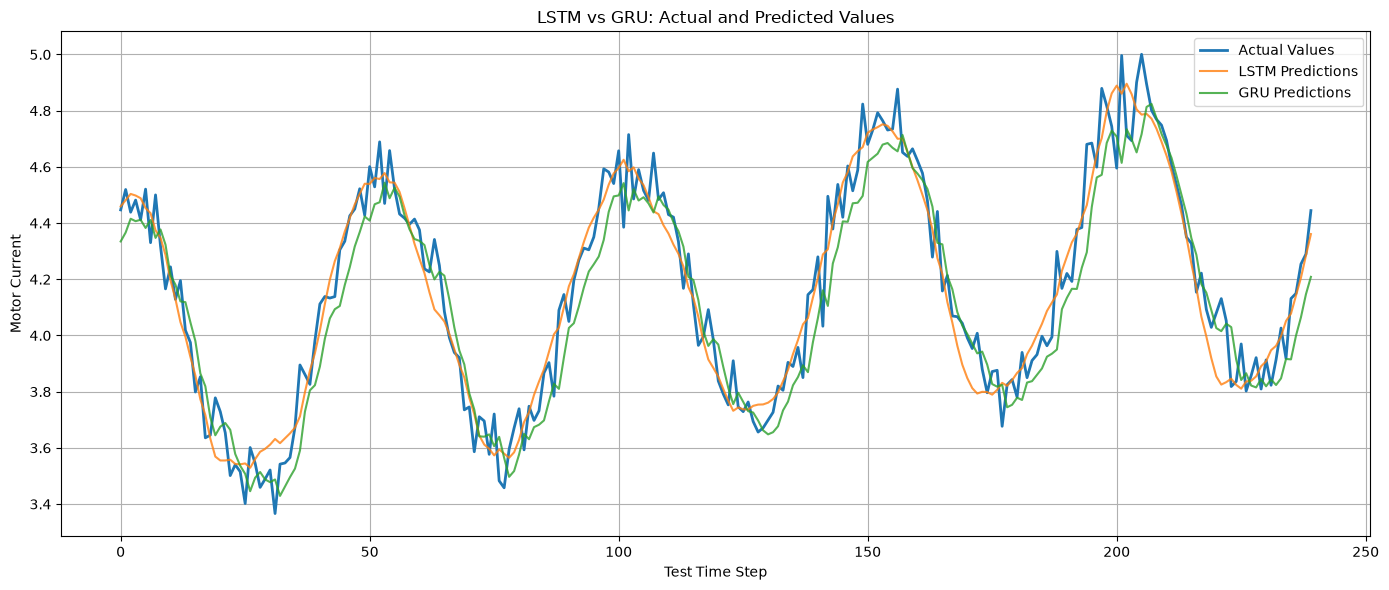


NEXT READING PREDICTIONS
LSTM predicted next motor current: 4.4570
GRU predicted next motor current: 4.3080

Saved files:
1. lstm_motor_current.keras
2. gru_motor_current.keras
3. model_comparison.csv

PROJECT COMPLETED!


In [6]:
# ============================================================
# LSTM vs GRU: Time-Series Forecasting
# Project: LSTM-GRU-Practice
# ============================================================

# STEP 1: Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


# STEP 2: Create a sample dataset
# Real project lo ee section ni CSV loading tho replace cheyochu.

np.random.seed(42)

total_points = 1200

time = np.arange(total_points)

# Example: motor current readings
trend = 0.002 * time
seasonal_pattern = 0.5 * np.sin(2 * np.pi * time / 50)
small_variation = np.random.normal(0, 0.08, total_points)

motor_current = (
    2.0
    + trend
    + seasonal_pattern
    + small_variation
)

df = pd.DataFrame({
    "time": time,
    "motor_current": motor_current
})

print("\nFirst five rows of dataset:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nDataset information:")
print(df.info())


# STEP 3: Visualize the dataset

plt.figure(figsize=(12, 4))

plt.plot(
    df["time"],
    df["motor_current"],
    label="Motor Current"
)

plt.title("Motor Current Time Series")
plt.xlabel("Time Step")
plt.ylabel("Motor Current")
plt.legend()
plt.grid(True)
plt.show()


# STEP 4: Separate the data

values = df[["motor_current"]].values

# Time-series data lo future information train data loki raakunda
# chronological split use chestham.

split_index = int(len(values) * 0.80)

train_data = values[:split_index]
test_data = values[split_index:]


# STEP 5: Scale the data

scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(train_data)

# Test data ni training data scaler tho transform chestham.
test_scaled = scaler.transform(test_data)

print("\nTraining data shape:", train_scaled.shape)
print("Testing data shape:", test_scaled.shape)


# STEP 6: Create sequences

# Previous 30 readings use chesi next reading predict chestham.

LOOKBACK = 30


def create_sequences(data, lookback):

    X = []
    y = []

    for i in range(lookback, len(data)):

        X.append(data[i - lookback:i])
        y.append(data[i])

    X = np.array(X)
    y = np.array(y)

    return X, y


# Training sequences

X_train, y_train = create_sequences(
    train_scaled,
    LOOKBACK
)


# Testing sequences kosam training data lo last 30 readings
# context ga use chestham.

combined_test = np.concatenate([
    train_scaled[-LOOKBACK:],
    test_scaled
])

X_test, y_test = create_sequences(
    combined_test,
    LOOKBACK
)


print("\nX_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)


# Expected shape:
# Samples x 30 time steps x 1 feature


# STEP 7: Define LSTM model

def build_lstm_model():

    model = Sequential([
        Input(shape=(LOOKBACK, 1)),

        LSTM(32),

        Dropout(0.2),

        Dense(16, activation="relu"),

        Dense(1)
    ])

    model.compile(
        optimizer="adam",
        loss="mse"
    )

    return model


# STEP 8: Define GRU model

def build_gru_model():

    model = Sequential([
        Input(shape=(LOOKBACK, 1)),

        GRU(32),

        Dropout(0.2),

        Dense(16, activation="relu"),

        Dense(1)
    ])

    model.compile(
        optimizer="adam",
        loss="mse"
    )

    return model


# STEP 9: Create both models

lstm_model = build_lstm_model()
gru_model = build_gru_model()

print("\nLSTM MODEL SUMMARY")
lstm_model.summary()

print("\nGRU MODEL SUMMARY")
gru_model.summary()


# STEP 10: Configure early stopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)


# STEP 11: Train LSTM

print("\nTraining LSTM model...")

lstm_history = lstm_model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=1
)


# STEP 12: Train GRU

print("\nTraining GRU model...")

gru_history = gru_model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=1
)


# STEP 13: Generate predictions

print("\nGenerating predictions...")

lstm_pred_scaled = lstm_model.predict(
    X_test,
    verbose=0
)

gru_pred_scaled = gru_model.predict(
    X_test,
    verbose=0
)


# STEP 14: Convert scaled values to original scale

lstm_predictions = scaler.inverse_transform(
    lstm_pred_scaled
).flatten()

gru_predictions = scaler.inverse_transform(
    gru_pred_scaled
).flatten()

actual_values = scaler.inverse_transform(
    y_test
).flatten()


# STEP 15: Evaluate model performance

def evaluate_model(name, actual, predicted):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    mse = mean_squared_error(
        actual,
        predicted
    )

    rmse = np.sqrt(mse)

    print(f"\n{name} RESULTS")

    print(f"MAE  : {mae:.4f}")
    print(f"MSE  : {mse:.4f}")
    print(f"RMSE : {rmse:.4f}")

    return {
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse
    }


lstm_results = evaluate_model(
    "LSTM",
    actual_values,
    lstm_predictions
)

gru_results = evaluate_model(
    "GRU",
    actual_values,
    gru_predictions
)


# STEP 16: Compare both models

results_df = pd.DataFrame([
    lstm_results,
    gru_results
])

print("\nMODEL COMPARISON")
print(results_df.to_string(index=False))


# STEP 17: Plot actual vs predicted values

plt.figure(figsize=(14, 6))

plt.plot(
    actual_values,
    label="Actual Values",
    linewidth=2
)

plt.plot(
    lstm_predictions,
    label="LSTM Predictions",
    alpha=0.8
)

plt.plot(
    gru_predictions,
    label="GRU Predictions",
    alpha=0.8
)

plt.title("LSTM vs GRU: Actual and Predicted Values")
plt.xlabel("Test Time Step")
plt.ylabel("Motor Current")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# STEP 18: Predict the next value using the latest 30 readings

latest_sequence = values[-LOOKBACK:]

latest_scaled = scaler.transform(
    latest_sequence
)

latest_input = latest_scaled.reshape(
    1,
    LOOKBACK,
    1
)


lstm_next_scaled = lstm_model.predict(
    latest_input,
    verbose=0
)

gru_next_scaled = gru_model.predict(
    latest_input,
    verbose=0
)


lstm_next_value = scaler.inverse_transform(
    lstm_next_scaled
)[0, 0]

gru_next_value = scaler.inverse_transform(
    gru_next_scaled
)[0, 0]


print("\nNEXT READING PREDICTIONS")

print(
    f"LSTM predicted next motor current: "
    f"{lstm_next_value:.4f}"
)

print(
    f"GRU predicted next motor current: "
    f"{gru_next_value:.4f}"
)


# STEP 19: Save trained models

lstm_model.save("lstm_motor_current.keras")

gru_model.save("gru_motor_current.keras")

results_df.to_csv(
    "model_comparison.csv",
    index=False
)

print("\nSaved files:")
print("1. lstm_motor_current.keras")
print("2. gru_motor_current.keras")
print("3. model_comparison.csv")

print("\nPROJECT COMPLETED!")